# Updated Basline Model 

This notebook fixes the target label class, and introduces a new class for neutral responses

**Target:** scores **1–3 = satisfied**, **4 = neutral**, and **5–7 = dissatisfied**. These groupings describe survey responses; the numeric class codes are identifiers, not distances between classes.

**Input:** `data/constructed_datasets/issp_onet_baseline_us.csv`. Results describe this cleaned US sample, not weighted population estimates or causal effects of job fit.


In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Load the merged data

Find the repository root from the current working directory so the notebook works when launched from either the project root or this notebook's folder. The inputs are read only; outputs are kept in memory.

In [2]:
cwd = Path.cwd().resolve()
ROOT = next(
    (parent for parent in (cwd, *cwd.parents)
     if (parent / 'data/constructed_datasets/issp_onet_baseline_us.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'Could not find data/constructed_datasets/issp_onet_baseline_us.csv '
        'in the current directory or its parents. Open the project folder as the workspace.'
    )

DATA_PATH = ROOT / 'data/constructed_datasets/issp_onet_baseline_us.csv'
JOBZONE_PATH = ROOT / 'data/formatted_onet/formatted_jobzones.csv'
df = pd.read_csv(DATA_PATH, dtype={'ONET_SOC_CODE': 'string'})
print(f'Project root: {ROOT}')
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Project root: /Users/ak101/Desktop/BTT_FALL_AI_PROJECT/Swytch-2A-predicting-job-satisfaction-from-person-job-fit
Dataset shape: 2,040 rows × 44 columns


,ONET_SOC_CODE,module_year,job_satisfaction,age,sex,marital_status,educ_years,educ_level,household_income_group,hours_worked_weekly,employment_status_current,union_member,household_size,child_in_household,urban_rural,imp_job_security,imp_income,imp_advancement,imp_interesting,imp_independence,imp_help_others,imp_useful_society,imp_decide_hours,actual_job_secure,actual_income_high,actual_advancement_high,actual_job_interesting,actual_work_independently,actual_help_others,actual_useful_society,onet_job_zone,career_interest_types_OI_artistic_value,career_interest_types_OI_conventional_value,career_interest_types_OI_enterprising_value,career_interest_types_OI_investigative_value,career_interest_types_OI_realistic_value,career_interest_types_OI_social_value,fit_gap_security,fit_gap_income,fit_gap_advancement,fit_gap_interesting,fit_gap_independence,fit_gap_help_others,fit_gap_useful_society
0,25-2056.00,1997.0,5.0,33.0,1.0,3.0,16.0,4.0,2.0,40.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,4.0,4.0,2.0,2.0,1.0,1.0,4.0,3.65,3.48,1.77,3.94,2.27,7.00,-1.0,-3.0,-2.0,0.0,0.0,1.0,1.0
1,45-2011.00,1997.0,3.0,43.0,1.0,4.0,12.0,3.0,3.0,40.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.00,5.17,3.12,4.04,5.35,1.89,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
2,17-2071.00,1997.0,4.0,45.0,1.0,3.0,15.0,4.0,3.0,50.0,1.0,3.0,1.0,2.0,1.0,2.0,2.0,3.0,2.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,4.0,2.12,4.43,2.44,5.45,6.02,1.72,-1.0,-1.0,-1.0,-2.0,0.0,-2.0,-1.0
3,11-3031.00,1997.0,1.0,42.0,1.0,1.0,16.0,4.0,1.0,50.0,1.0,3.0,5.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,4.0,1.59,5.56,7.00,2.46,1.36,3.04,0.0,0.0,0.0,-1.0,0.0,0.0,0.0
4,41-2031.00,1997.0,1.0,36.0,2.0,5.0,15.0,3.0,3.0,50.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,4.0,3.0,1.0,1.0,2.0,2.0,2.0,1.98,5.17,6.13,1.00,3.20,2.96,1.0,-2.0,-1.0,1.0,1.0,0.0,0.0


## 2. Data quality and final cleaning checks

Normalize occupation-code whitespace/case, validate the expected O*NET-SOC shape, and compare codes to the formatted O*NET job-zone lookup. Unmatched or malformed codes are reported rather than silently deleting survey records. Exact duplicate rows and rows without a usable target are removed before analysis.

In [3]:
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('\nMissing values by column (non-zero only):')
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].rename('missing_count').to_frame().assign(
    missing_pct=lambda x: (100 * x['missing_count'] / len(df)).round(1)
))

if 'ONET_SOC_CODE' not in df:
    raise KeyError('The merged input is missing required occupation key ONET_SOC_CODE.')
df['ONET_SOC_CODE'] = df['ONET_SOC_CODE'].astype('string').str.strip().str.upper()
df['ONET_SOC_CODE'] = df['ONET_SOC_CODE'].replace('', pd.NA)
onet_code_pattern = re.compile(r'^\d{2}-\d{4}\.\d{2}$')
valid_code = df['ONET_SOC_CODE'].str.fullmatch(onet_code_pattern, na=False)
print(f"\nMissing occupation codes: {df['ONET_SOC_CODE'].isna().sum():,}")
print(f'Malformed occupation codes: {(df["ONET_SOC_CODE"].notna() & ~valid_code).sum():,}')
display(df.loc[df['ONET_SOC_CODE'].notna() & ~valid_code, ['ONET_SOC_CODE']].head(10))

if JOBZONE_PATH.is_file():
    jobzones = pd.read_csv(JOBZONE_PATH, dtype={'ONET_SOC_CODE': 'string'})
    if 'ONET_SOC_CODE' not in jobzones:
        raise KeyError('The O*NET job-zone lookup is missing ONET_SOC_CODE.')
    jobzones['ONET_SOC_CODE'] = jobzones['ONET_SOC_CODE'].astype('string').str.strip().str.upper()
    lookup_codes = set(jobzones['ONET_SOC_CODE'].dropna())
    duplicate_lookup_codes = int(jobzones['ONET_SOC_CODE'].duplicated().sum())
    valid_codes = set(df.loc[valid_code, 'ONET_SOC_CODE'].dropna())
    unmatched_codes = sorted(valid_codes - lookup_codes)
    unmatched_rows = df['ONET_SOC_CODE'].isin(unmatched_codes)
    print(f'O*NET lookup rows: {len(jobzones):,}; duplicate lookup keys: {duplicate_lookup_codes:,}')
    print(f'Unique valid survey codes: {len(valid_codes):,}; unmatched unique codes: {len(unmatched_codes):,}')
    print(f'Survey rows with unmatched valid codes: {int(unmatched_rows.sum()):,}')
    display(pd.Series(unmatched_codes, name='unmatched_ONET_SOC_CODE').to_frame().head(20))
else:
    warnings.warn(f'O*NET lookup not found at {JOBZONE_PATH}; code-format validation still ran.')

Exact duplicate rows: 0

Missing values by column (non-zero only):


,missing_count,missing_pct



Missing occupation codes: 0
Malformed occupation codes: 0


,ONET_SOC_CODE


O*NET lookup rows: 923; duplicate lookup keys: 0
Unique valid survey codes: 225; unmatched unique codes: 0
Survey rows with unmatched valid codes: 0


,unmatched_ONET_SOC_CODE


## 3. Prepare the three-class target

Use explicit mappings: class 0 = satisfied (scores 1–3), class 1 = neutral (score 4), class 2 = dissatisfied (scores 5–7). Kept neutral respondents rather than assigning them to either extreme.

In [5]:
TARGET = 'job_satisfaction'
CLASS_NAMES = ['satisfied (1–3)', 'neutral (4)', 'dissatisfied (5–7)']
CLASS_CODES = [0, 1, 2]
SCORE_TO_CLASS = {1: 0, 2: 0, 3: 0, 4: 1, 5: 2, 6: 2, 7: 2}
if not df[TARGET].isin(SCORE_TO_CLASS).all():
    raise ValueError('Expected integer satisfaction scores from 1 through 7.')
df['satisfaction_class'] = df[TARGET].map(SCORE_TO_CLASS).astype('int8')
print('Original seven-point response distribution:')
display(df[TARGET].value_counts().sort_index().rename('count').to_frame())
class_counts = df['satisfaction_class'].value_counts().reindex(CLASS_CODES, fill_value=0)
class_summary = class_counts.rename('count').to_frame()
class_summary['percent'] = (100 * class_summary['count'] / len(df)).round(2)
class_summary.index = CLASS_NAMES
print('Three-class target distribution:')
display(class_summary)

categorical_candidates = [
    'module_year', 'sex', 'marital_status', 'educ_level', 'household_income_group',
    'employment_status_current', 'union_member', 'urban_rural',
]
categorical_features = [column for column in categorical_candidates if column in df.columns]
identifier_columns = {
    column for column in df.columns
    if column.upper() in {'ID', 'ID_', 'ENTITY_ID', 'RESPONDENT_ID', 'CASEID'}
    or column.upper().endswith('_ID')
}
excluded_features = {TARGET, 'satisfaction_class', 'ONET_SOC_CODE'} | identifier_columns
feature_columns = [column for column in df.columns if column not in excluded_features]

# Convert selected coded categories to consistent strings before one-hot encoding.
X = df[feature_columns].copy()
for column in categorical_features:
    X[column] = X[column].astype('string').str.strip().replace('', pd.NA).astype(object)
    X[column] = X[column].where(pd.notna(X[column]), np.nan)
y = df['satisfaction_class']

numeric_features = [column for column in X.select_dtypes(include='number').columns]
categorical_features = [column for column in categorical_features if column in X.columns]
unused_features = [column for column in X.columns if column not in numeric_features + categorical_features]
if unused_features:
    print('Excluding non-numeric, non-categorical columns:', unused_features)
    X = X.drop(columns=unused_features)

print(f'Predictors: {X.shape[1]} ({len(numeric_features)} numeric, {len(categorical_features)} categorical)')
print('Excluded identifiers:', sorted(identifier_columns))
print('Raw occupation code excluded:', 'ONET_SOC_CODE' in excluded_features)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print(f'Train rows: {len(X_train):,}; test rows: {len(X_test):,}')

Original seven-point response distribution:


,count
job_satisfaction,
1.0,356
2.0,712
3.0,662
4.0,135
5.0,110
6.0,49
7.0,16


Three-class target distribution:


,count,percent
satisfied (1–3),1730,84.80
neutral (4),135,6.62
dissatisfied (5–7),175,8.58


Predictors: 42 (34 numeric, 8 categorical)
Excluded identifiers: []
Raw occupation code excluded: True
Train rows: 1,530; test rows: 510


In [6]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore')),
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features),
    ], remainder='drop')

models = {
    'Logistic regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision tree': DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random forest': RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    ),
}
pipelines = {
    name: Pipeline([('preprocessor', make_preprocessor()), ('model', model)])
    for name, model in models.items()
}
print('Model pipelines are ready.')

Model pipelines are ready.


## 4. Train and compare three-class baselines

Replace binary positive-class precision, recall, and F1 with **macro averages**, which give satisfied, neutral, and dissatisfied equal weight. Balanced accuracy is mean recall across the three classes. Report per-class metrics and confusion matrices to expose weak performance on neutral and dissatisfied respondents. ROC AUC uses macro one-vs-rest probabilities for all three classes.

MacroF1 is used since the satisfied class mostly dominates the dataset. MacroF1 calculates the F1 score for the indiviual target class, instead of considering the target class porportion of the entire dataset.

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc
model,,,,,,
Random forest,0.749,0.526,0.454,0.526,0.470,0.726
Decision tree,0.702,0.473,0.416,0.473,0.424,0.657
Logistic regression,0.610,0.419,0.393,0.419,0.379,0.679


Always-satisfied reference:
Accuracy: 0.847; balanced accuracy: 0.333; macro F1: 0.306


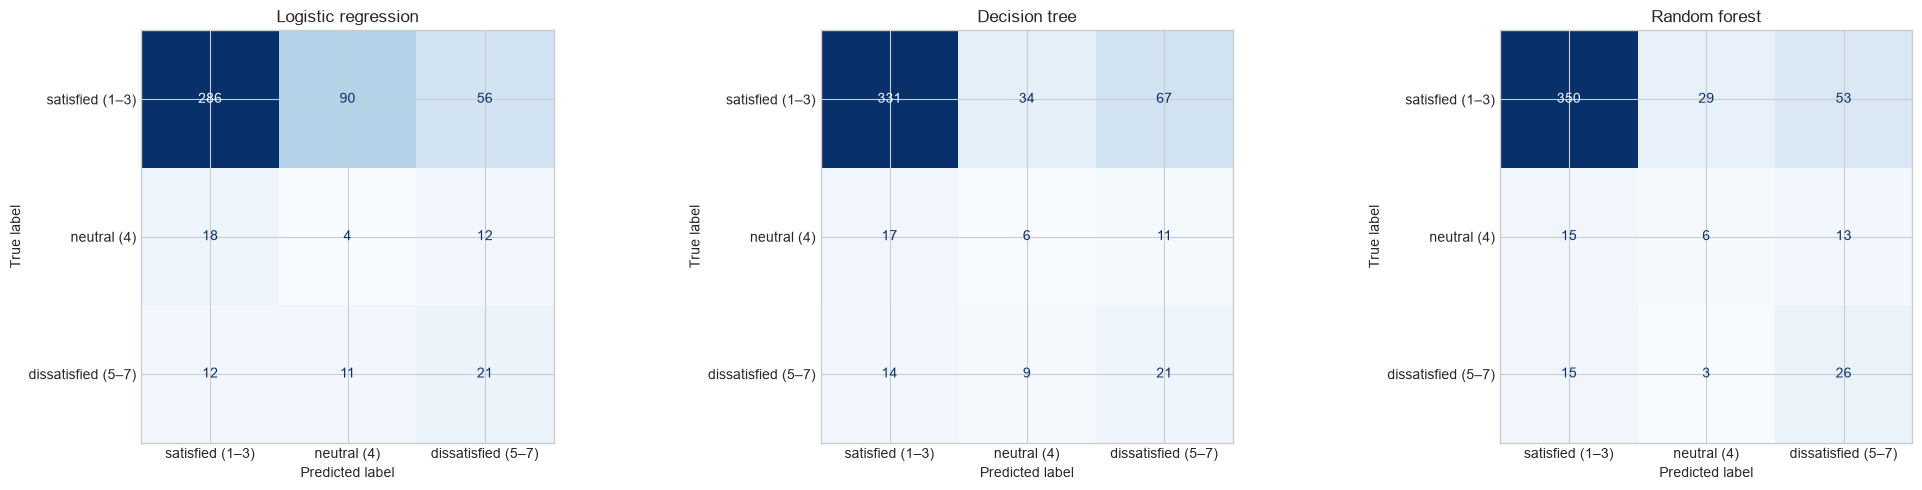

In [7]:
results = []
predictions = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)
    predictions[name] = predicted
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predicted),
        'balanced_accuracy': balanced_accuracy_score(y_test, predicted),
        'precision_macro': precision_score(y_test, predicted, average='macro', zero_division=0),
        'recall_macro': recall_score(y_test, predicted, average='macro', zero_division=0),
        'f1_macro': f1_score(y_test, predicted, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y_test, probabilities, labels=CLASS_CODES, multi_class='ovr', average='macro'),
    })
results_df = pd.DataFrame(results).set_index('model').sort_values('f1_macro', ascending=False)
display(results_df.round(3))
always_satisfied = np.zeros(len(y_test), dtype='int8')
print('Always-satisfied reference:')
print(f'Accuracy: {accuracy_score(y_test, always_satisfied):.3f}; '
      f'balanced accuracy: {balanced_accuracy_score(y_test, always_satisfied):.3f}; '
      f'macro F1: {f1_score(y_test, always_satisfied, average="macro", zero_division=0):.3f}')

fig, axes = plt.subplots(1, len(pipelines), figsize=(7 * len(pipelines), 5))
for ax, (name, predicted) in zip(np.atleast_1d(axes), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=CLASS_CODES, display_labels=CLASS_NAMES, cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [8]:
for name, pipeline in pipelines.items():
    print(f'\n{name} — test-set classification report')
    print(classification_report(y_test, predictions[name], labels=CLASS_CODES, target_names=CLASS_NAMES, zero_division=0))


Logistic regression — test-set classification report
                    precision    recall  f1-score   support

   satisfied (1–3)       0.91      0.66      0.76       432
       neutral (4)       0.04      0.12      0.06        34
dissatisfied (5–7)       0.24      0.48      0.32        44

          accuracy                           0.61       510
         macro avg       0.39      0.42      0.38       510
      weighted avg       0.79      0.61      0.68       510


Decision tree — test-set classification report
                    precision    recall  f1-score   support

   satisfied (1–3)       0.91      0.77      0.83       432
       neutral (4)       0.12      0.18      0.14        34
dissatisfied (5–7)       0.21      0.48      0.29        44

          accuracy                           0.70       510
         macro avg       0.42      0.47      0.42       510
      weighted avg       0.80      0.70      0.74       510


Random forest — test-set classification report
    

## 5. Summary

- **Corrected the target direction:** scores 1–3 are satisfied, 4 is neutral, and 5–7 are dissatisfied. The original 8.6% figure described dissatisfied respondents, not satisfied respondents.
- **Preserved neutral responses:** neutral is a separate outcome. The cleaned dataset has 1,730 satisfied (84.80%), 135 neutral (6.62%), and 175 dissatisfied (8.58%) respondents. These are unweighted counts.
- **Updated evaluation:** macro precision/recall/F1, multiclass ROC AUC, three-class confusion matrices, and per-class reports replace binary satisfied-class metrics. The original binary F1 and AUC cannot be directly compared with these multiclass metrics.

### Limits and next steps

Class imbalance still exists, with only 135 neutral respondents. We need to explore repeated stratified cross-validation for more stable comparisons and assess performance by demographic subgroup. For job-fit trends, we can also inspect the original ISSP seven-point responses and distinguish predictive association from causation. 